<a href="https://colab.research.google.com/github/kelvin144-netizen/albert-hackathon-design-challenge/blob/main/Copy_of_tema_02b_vizualizarea_datelor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


##    <center>Tema 2b: Vizualizarea datelor</center>
**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>


In [50]:
df_ex1 = incarca("lab-set4")[0]
df_ex1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [16]:
df_ex1["Revenue"] = df_ex1["Quantity"] * df_ex1["UnitPrice"]

(
    df_ex1.groupby(["StockCode", "Description"], dropna=False)["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

,,Revenue
StockCode,Description,
DOT,DOTCOM POSTAGE,206245.48
22423,REGENCY CAKESTAND 3 TIER,164762.19
47566,PARTY BUNTING,98302.98
85123A,WHITE HANGING HEART T-LIGHT HOLDER,97715.99
85099B,JUMBO BAG RED RETROSPOT,92356.03
23084,RABBIT NIGHT LIGHT,66756.59
POST,POSTAGE,66230.64
22086,PAPER CHAIN KIT 50'S CHRISTMAS,63791.94
84879,ASSORTED COLOUR BIRD ORNAMENT,58959.73


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/02-explorare-vizualizare/tema-02b-vizualizarea-datelor.ipynb)

In [17]:
# 1. Remove obvious non-product codes & descriptions (postage, fees, manual adjustments, discounts)
non_product_codes = {"DOT", "POST", "M", "BANK CHARGES", "AMAZONFEE", "CRUK", "B", "S", "PADS"}

code_clean = df_ex1["StockCode"].astype(str).str.upper().str.strip()
desc_clean = df_ex1["Description"].fillna("").str.upper().str.strip()

is_non_product = (
    code_clean.isin(non_product_codes)
    | desc_clean.str.contains("POSTAGE|MANUAL|BANK CHARGES|AMAZON FEE|DISCOUNT|ADJUST", regex=True)
    | df_ex1["Description"].isna()
)

df_clean = df_ex1[~is_non_product & (df_ex1["UnitPrice"] > 0)].copy()
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# 2. Check top 5 products (net revenue: keeps negative Quantity returns so they subtract from revenue)
top_products = (
    df_clean.groupby(["StockCode", "Description"])["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 5 products (net revenue, including returns):")
print(top_products.head(5))

print("\nHow many return rows (Quantity < 0) are in cleaned products?", (df_clean["Quantity"] < 0).sum())

Top 5 products (net revenue, including returns):
StockCode  Description                       
22423      REGENCY CAKESTAND 3 TIER              164762.19
47566      PARTY BUNTING                          98302.98
85123A     WHITE HANGING HEART T-LIGHT HOLDER     97715.99
85099B     JUMBO BAG RED RETROSPOT                92356.03
23084      RABBIT NIGHT LIGHT                     66756.59
Name: Revenue, dtype: float64

How many return rows (Quantity < 0) are in cleaned products? 8706


In [5]:
# Configurare curs SEED: rulați această celulă prima.
# Colab: descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
# Local: găsește singură rădăcina repository-ului, oricare ar fi folderul curent al kernelului.
import os, sys
MODUL = "02-explorare-vizualizare"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    RADACINA = "/content/SEED"
else:
    RADACINA = os.path.abspath(".")
    while not os.path.isdir(os.path.join(RADACINA, "seed")) and os.path.dirname(RADACINA) != RADACINA:
        RADACINA = os.path.dirname(RADACINA)
    import importlib.util, socket
    lipsa = [p for p in ("pandas", "matplotlib", "seaborn", "sklearn") if importlib.util.find_spec(p) is None]
    if lipsa:
        print("Lipsesc pachetele", lipsa, "- în terminal: pip install -r requirements-local.txt")
    try:
        socket.create_connection(("raw.githubusercontent.com", 443), 2).close()
    except OSError:
        print("Fără internet: imaginile din text nu se văd. O singură dată, în terminal: python tools/imagini_offline.py")
os.chdir(os.path.join(RADACINA, "cursuri", MODUL))
sys.path.insert(0, RADACINA)

YearMonth
2010-12    26897.36
2011-01    11742.50
2011-02    10466.04
2011-03    16830.60
2011-04    14280.90
2011-05    12217.27
2011-06     9466.39
2011-07    13777.56
2011-08     8406.30
2011-09     9315.03
2011-10    12660.84
2011-11    12798.48
2011-12     5902.92
Name: Revenue, dtype: float64


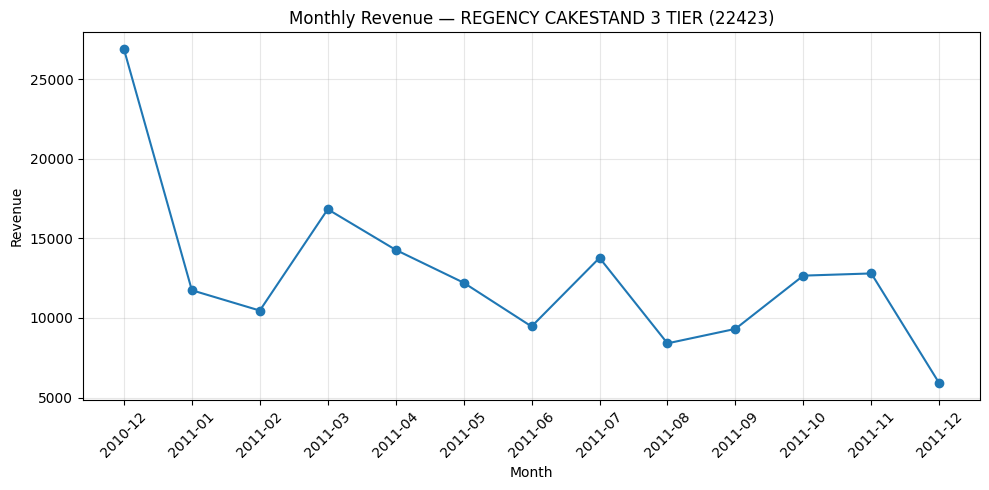

In [18]:
best_code = "22423"
best_desc = "REGENCY CAKESTAND 3 TIER"

df_best = df_clean[df_clean["StockCode"].astype(str).str.strip() == best_code].copy()

# Convert InvoiceDate to datetime, then extract Year-Month (e.g., "2011-04")
df_best["InvoiceDate"] = pd.to_datetime(df_best["InvoiceDate"])
df_best["YearMonth"] = df_best["InvoiceDate"].dt.to_period("M").astype(str)

# Sum revenue per month in chronological order
monthly_rev = df_best.groupby("YearMonth")["Revenue"].sum().sort_index()
print(monthly_rev)

# Plot monthly revenue
plt.figure(figsize=(10, 5))
plt.plot(monthly_rev.index, monthly_rev.values, marker="o")
plt.title(f"Monthly Revenue — {best_desc} ({best_code})")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
import os, sys
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/SEED'):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    sys.path.insert(0, '/content/SEED')

from seed.date import incarca

Explanation (Exercise 1): Before filtering, DOTCOM POSTAGE (DOT) appeared first by revenue (206,245.48), even though it is a shipping fee rather than a physical product. After removing non-product codes/descriptions (such as postage, fees, manual adjustments, and missing descriptions) and invalid/non-positive prices (UnitPrice <= 0), the top-selling product is REGENCY CAKESTAND 3 TIER (22423) with 164,762.19 in net revenue. I kept return rows (Quantity < 0) when calculating net revenue so customer returns subtract accurately from total sales, while still showing true product performance. The monthly chart shows strong demand in December 2010 (2010-12), secondary peaks in March (2011-03) and July (2011-07), and a drop at the end of the dataset in December 2011 (2011-12).

## Cum lucrezi la această temă

1. Deschide notebook-ul:
   - în **Colab** (butonul **Open in Colab**) și salvează-ți o copie: **File → Save a copy in Drive**; vezi [ghidul Colab](https://github.com/sbildea/SEED/blob/main/docs/ghid-colab.md);
   - sau **local**, în VS Code, pe o copie a fișierului (merge și fără internet); vezi [ghidul local](https://github.com/sbildea/SEED/blob/main/docs/ghid-local.md).
2. Rulează celula **Configurare curs** de mai sus. Datele se încarcă apoi cu o singură linie, de exemplu `incarca("lab-set4")`.
3. Pentru fiecare exercițiu:
   - citește conceptul din curs și formulează **în cuvintele tale** ce vrei să obții și de ce;
   - cere codul unui asistent AI (Gemini din Colab, Claude, ChatGPT etc.) printr-o cerere în limbaj natural; vezi [ghidul de programare asistată de AI](https://github.com/sbildea/SEED/blob/main/docs/ghid-programare-asistata-ai.md);
   - rulează codul și **verifică rezultatul**: are sens? se potrivește cu datele? Corectează cererea dacă e nevoie;
   - notează în **Jurnalul AI** de la finalul notebook-ului cererile importante și ce ai verificat.
4. Redenumește fișierul conform indicațiilor din Prezentarea generală și predă-l.

> Evaluarea pune accentul pe înțelegerea conceptelor: trebuie să poți explica fiecare rezultat și de ce ai ales metoda respectivă.

> Întrebări: teodor.bildea@unitbv.ro

## Etica universitară

### Colaborare vs plagiat

Colaborarea între voi este încurajată atât timp cât nu cade în categoria plagiatului așa cum este descris în statutul studentului.

Copiatul/plagiatul și orice altă formă de incorectitudine academică nu vor fi tolerate și vor fi sancționate conform statutului studentului.

# Exerciții: vizualizarea datelor

Import module necesare

In [7]:
import pandas as pd
import numpy as np
import sqlite3
import os
import seaborn as sns # visualize
import matplotlib.pyplot as plt
import plotly.graph_objects as go

## Citirea datelor

Seturile de date se încarcă cu funcția `incarca` din pachetul cursului, la fel în Colab și pe calculatorul vostru. Nu trebuie descărcat nimic manual și nu trebuie modificată nicio cale:

```python
date = incarca("lab-set4")   # toate tabelele setului 4
df = date[0]                 # primul tabel (sau după nume: date["OnlineRetail"])
```

In [8]:
# Citirea datelor de laborator: nu trebuie modificată nicio cale.
# incarca("lab-set4") descarcă setul (doar prima dată) și întoarce tabelele lui;
# un tabel se alege după nume sau după poziție: date["OnlineRetail"] sau date[0].
from seed.date import incarca, lista_seturi
lista_seturi("lab")

lab-set1    Telco Customer Churn - clienți care renunță la abonament
lab-set2    HR Analytics - plecarea angajaților (5 tabele, cheie EmployeeID)
lab-set3    Consumul de alcool și performanța școlară (matematică, portugheză)
lab-set4    Online Retail - tranzacții magazin online (UCI)
lab-set5    Bank Loan Status - acordarea creditelor
lab-set6    House Prices - prețuri locuințe (Ames, Iowa)
lab-set7    Healthcare Provider Fraud - fraude la furnizori medicali (8 tabele)
lab-set8    European Soccer Database - meciuri și jucători (SQLite, 7 tabele)
lab-set9    Healthcare - predicția accidentului vascular cerebral
lab-set10   Medical Appointment No-Shows - neprezentarea la programări


### Exercițiul 1:

1. Pentru setul de date Set4 - OnlineRetail.xlsx - determinați cel mai bine vândut produs - produsul cu cel mai mare venit total realizat (venit = Quantity × UnitPrice).
2. Prezentați graficul de venit lunar pentru acel produs.

`Atenție` Verificați dacă primul rezultat chiar este un produs și decideți ce faceți cu liniile care nu sunt produse (taxe, poștă, ajustări) și cu retururile. Explicați alegerea făcută.

In [9]:
# codul vostru aici
df_ex1 = incarca("lab-set4")[0]
df_ex1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### Exercițiul 2

1. Folosind setul de date Set1 plotați un grafic cu plata medie lunară (Monthly Charges) pe categorii de Contract.
2. Faceți alt grafic în care introduceți gruparea (cu hue) pe gender.

In [10]:
# codul vostru aici
df_ex2 = incarca("lab-set1")[0]
df_ex2.info()

Descărcare lab-set1 (doar prima dată)...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  P

In [19]:
df_ex2 = incarca("lab-set1")[0]
df_ex2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


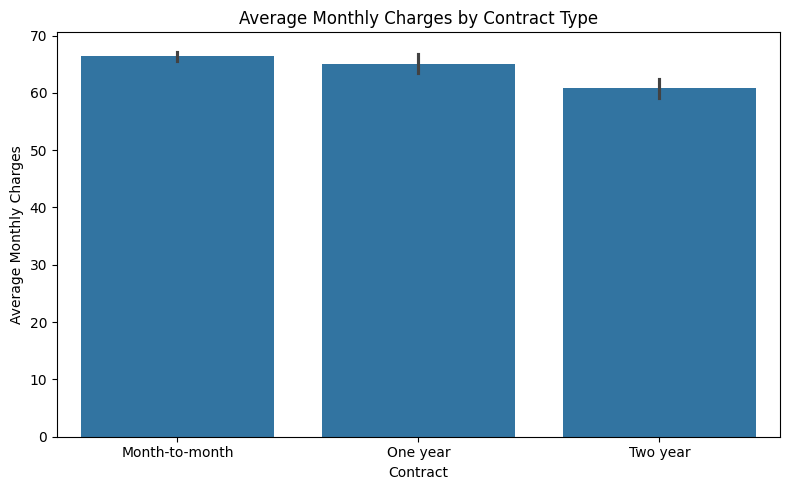

In [20]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_ex2, x="Contract", y="MonthlyCharges")
plt.title("Average Monthly Charges by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Average Monthly Charges")
plt.tight_layout()
plt.show()

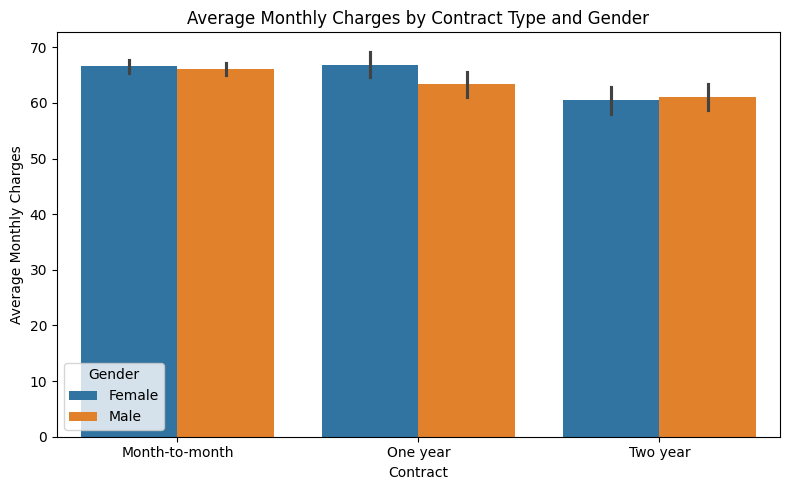

In [21]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_ex2, x="Contract", y="MonthlyCharges", hue="gender")
plt.title("Average Monthly Charges by Contract Type and Gender")
plt.xlabel("Contract")
plt.ylabel("Average Monthly Charges")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

###  Exercițiul 3

1. Folosind setul de date Set2, pe același grafic reprezentați distribuția venitului lunar (MonthlyIncome) pentru fiecare statut marital (MaritalStatus)


2. In grafice alaturate reprezentati distributia distantei fata de casa (DistanceFromHome) pentru fiecare statut marital

In [22]:
df_ex3 = incarca("lab-set2")[1]
df_ex3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   object 
 2   BusinessTravel           4410 non-null   object 
 3   Department               4410 non-null   object 
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   object 
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   object 
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   object 
 12  MaritalStatus            4410 non-null   object 
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked      

In [23]:
display(df_ex3[["MaritalStatus", "MonthlyIncome", "DistanceFromHome"]].head(10))
print("\nMaritalStatus counts:")
print(df_ex3["MaritalStatus"].value_counts(dropna=False))

,MaritalStatus,MonthlyIncome,DistanceFromHome
0,Married,131160,6
1,Single,41890,10
2,Married,193280,17
3,Married,83210,2
4,Single,23420,10
5,Married,40710,8
6,Single,58130,11
7,Married,31430,18
8,Married,20440,1
9,Divorced,134640,7



MaritalStatus counts:
MaritalStatus
Married     2019
Single      1410
Divorced     981
Name: count, dtype: int64


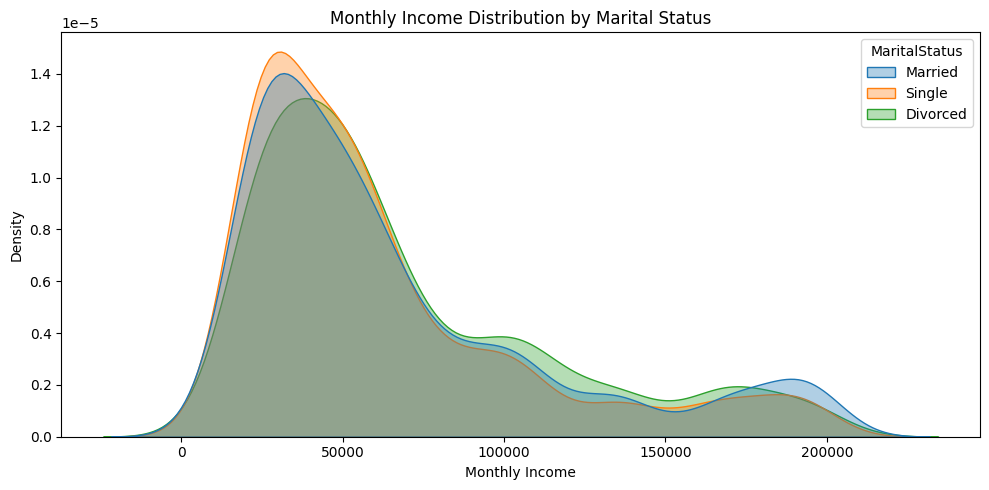

In [25]:
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=df_ex3,
    x="MonthlyIncome",
    hue="MaritalStatus",
    fill=True,
    common_norm=False,
    alpha=0.35
)
plt.title("Monthly Income Distribution by Marital Status")
plt.xlabel("Monthly Income")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

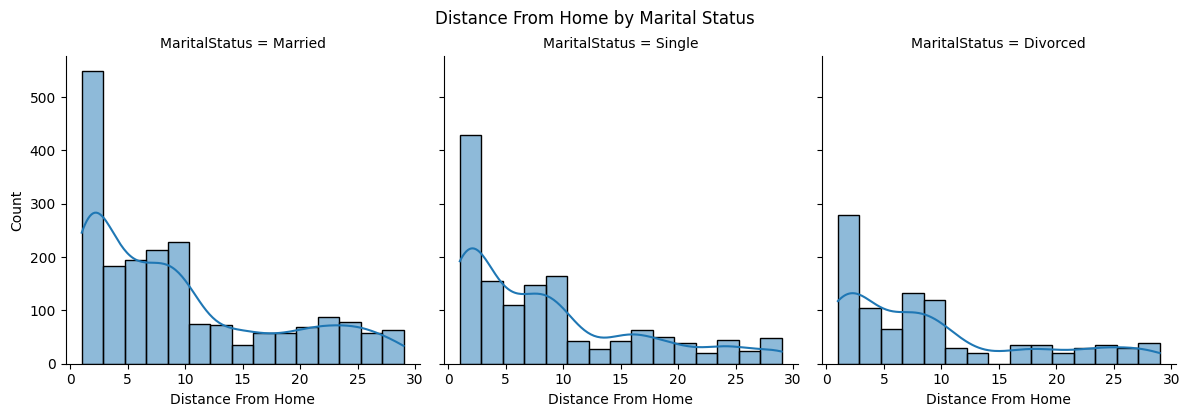

In [26]:
g = sns.displot(
    data=df_ex3,
    x="DistanceFromHome",
    col="MaritalStatus",
    bins=15,
    kde=True,
    height=4,
    aspect=1
)
g.fig.suptitle("Distance From Home by Marital Status", y=1.03)
g.set_axis_labels("Distance From Home", "Count")
plt.show()

In [11]:
# codul vostru aici
df_ex3 = incarca("lab-set2")[1]
df_ex3.info()

Descărcare lab-set2 (doar prima dată)...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   object 
 2   BusinessTravel           4410 non-null   object 
 3   Department               4410 non-null   object 
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   object 
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   object 
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   object 
 12  MaritalStatus            4410 non-null   object 
 13  MonthlyIncome            4410 non-nul

In [24]:
# cprint(df_ex3.groupby("MaritalStatus")["MonthlyIncome"].describe())odul vostru aici

### Exercițiul 4
Folosind setul de date Set3:

1. Reprezentați printr-un pie chart **proporția elevilor** (numărul de elevi) în funcție de ocupația tatălui (`Fjob`).
2. Reprezentați printr-un bar chart **timpul mediu de studiu** (`studytime`) în funcție de aceeași ocupație.
3. Repetați pentru nivelul de educație al mamei (`Medu`): pie chart cu numărul de elevi și bar chart cu timpul mediu până la școală (`traveltime`).

`Explicați` De ce este potrivit un pie chart pentru numărul de elevi, dar nu pentru timpul mediu? (Hint: ce ar însemna suma mediilor?)

In [28]:
df_ex4 = incarca("lab-set3")[0]
df_ex4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [13]:
# codul vostru aici
df_ex4 = incarca("lab-set3")[0]
df_ex4.info()

Descărcare lab-set3 (doar prima dată)...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery  

In [29]:
display(df_ex4[["Fjob", "studytime", "Medu", "traveltime"]].head(10))

print("\nFjob value counts:")
print(df_ex4["Fjob"].value_counts(dropna=False))

print("\nMedu value counts:")
print(df_ex4["Medu"].value_counts(dropna=False))

,Fjob,studytime,Medu,traveltime
0,teacher,2,4,2
1,other,2,1,1
2,other,2,1,1
3,services,3,4,1
4,other,2,3,1
5,other,2,4,1
6,other,2,2,1
7,teacher,2,4,2
8,other,2,3,1
9,other,2,3,1



Fjob value counts:
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64

Medu value counts:
Medu
4    131
2    103
3     99
1     59
0      3
Name: count, dtype: int64


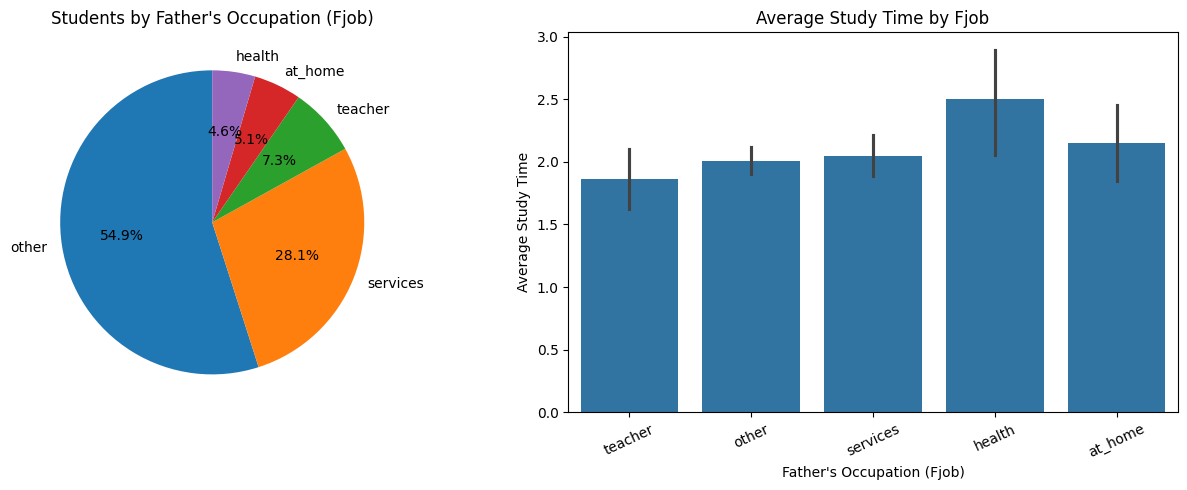

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Pie chart of student count by Fjob
fjob_counts = df_ex4["Fjob"].value_counts()
axes[0].pie(
    fjob_counts.values,
    labels=fjob_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Students by Father's Occupation (Fjob)")

# 2. Bar chart of average studytime by Fjob
sns.barplot(data=df_ex4, x="Fjob", y="studytime", ax=axes[1])
axes[1].set_title("Average Study Time by Fjob")
axes[1].set_xlabel("Father's Occupation (Fjob)")
axes[1].set_ylabel("Average Study Time")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

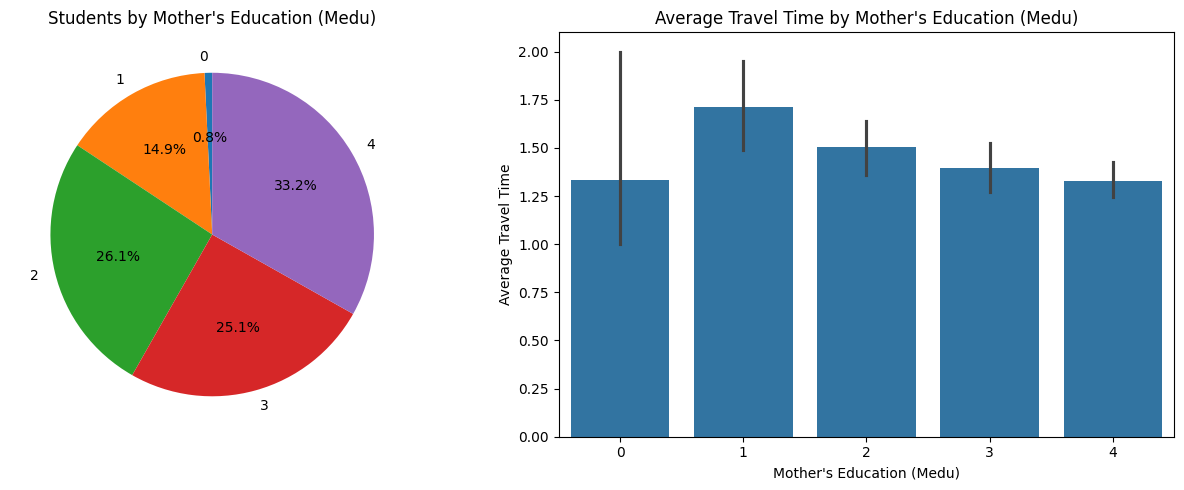

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Pie chart of student count by Medu
medu_counts = df_ex4["Medu"].value_counts().sort_index()
axes[0].pie(
    medu_counts.values,
    labels=medu_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Students by Mother's Education (Medu)")

# 2. Bar chart of average traveltime by Medu
sns.barplot(data=df_ex4, x="Medu", y="traveltime", ax=axes[1])
axes[1].set_title("Average Travel Time by Mother's Education (Medu)")
axes[1].set_xlabel("Mother's Education (Medu)")
axes[1].set_ylabel("Average Travel Time")

plt.tight_layout()
plt.show()

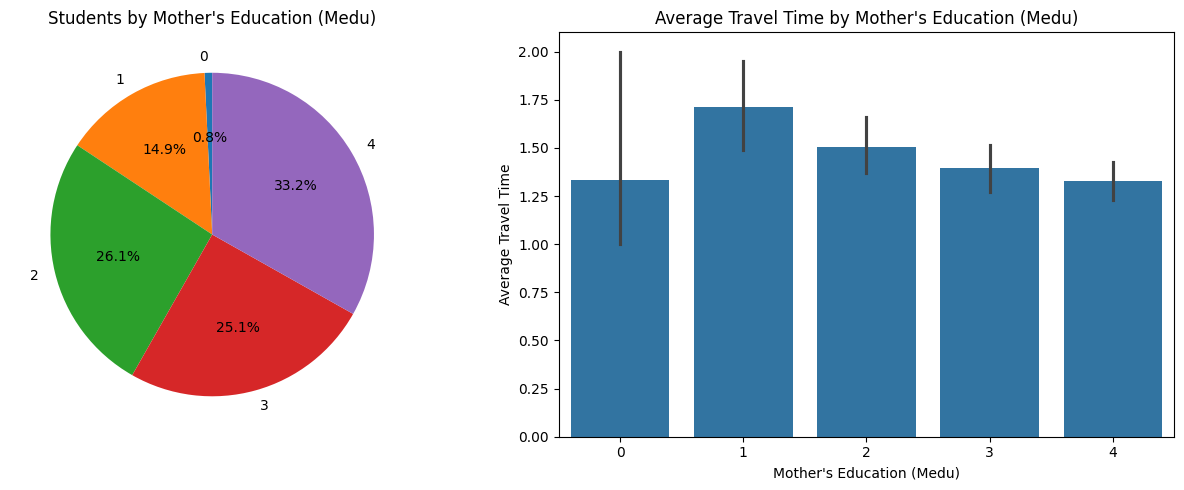

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Pie chart of student count by Medu
medu_counts = df_ex4["Medu"].value_counts().sort_index()
axes[0].pie(
    medu_counts.values,
    labels=medu_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Students by Mother's Education (Medu)")

# 2. Bar chart of average traveltime by Medu
sns.barplot(data=df_ex4, x="Medu", y="traveltime", ax=axes[1])
axes[1].set_title("Average Travel Time by Mother's Education (Medu)")
axes[1].set_xlabel("Mother's Education (Medu)")
axes[1].set_ylabel("Average Travel Time")

plt.tight_layout()
plt.show()

Explanation: A pie chart represents parts of a single whole (where each slice is a fraction of the total, summing to 100%). Student counts (value_counts()) add up to the total number of students in the dataset, so each slice genuinely shows that category's share of the whole. By contrast, averages (mean) of studytime or traveltime are separate group summaries, not pieces of one total—summing group averages has no meaningful interpretation (especially when groups have different sizes). A bar chart is better for comparing averages across categories.

In [27]:
df_ex4 = incarca("lab-set3")[0]
df_ex4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

### Exercițiul 5

1. Cu setul de date 5, tabelul `credit_train`, același ca la exemplul 5 din seminarul 2b, construiți un donut chart cu distribuția celor cu împrumut in funcție de o grupare pe anii în care au istoric de credit (Years of Credit History) - grupati anii in 5 grupe astfel:
- grupa 1: [0, 10) ani
- grupa 2: [10, 20) ani
- grupa 3: [20, 30) ani
- grupa 4: [30, 40) ani
- grupa 5: [40, infty) (>= 40 ani)


In [33]:
df_ex5.info()
display(df_ex5.head(10))

print("\nMissing values per column:")
print(df_ex5.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100514 entries, 0 to 100513
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loan ID                       100000 non-null  object 
 1   Customer ID                   100000 non-null  object 
 2   Loan Status                   100000 non-null  object 
 3   Current Loan Amount           100000 non-null  float64
 4   Term                          100000 non-null  object 
 5   Credit Score                  80846 non-null   float64
 6   Annual Income                 80846 non-null   float64
 7   Years in current job          95778 non-null   object 
 8   Home Ownership                100000 non-null  object 
 9   Purpose                       100000 non-null  object 
 10  Monthly Debt                  100000 non-null  float64
 11  Years of Credit History       100000 non-null  float64
 12  Months since last delinquent  46859 non-null

,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,14dd8831-6af5-400b-83ec-68e61888a048,981165ec-3274-42f5-a3b4-d104041a9ca9,Fully Paid,445412.0,Short Term,709.0,1167493.0,8 years,Home Mortgage,Home Improvements,5214.74,17.2,NaN,6.0,1.0,228190.0,416746.0,1.0,0.0
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328.0,Short Term,NaN,NaN,10+ years,Home Mortgage,Debt Consolidation,33295.98,21.1,8.0,35.0,0.0,229976.0,850784.0,0.0,0.0
2,4eed4e6a-aa2f-4c91-8651-ce984ee8fb26,5efb2b2b-bf11-4dfd-a572-3761a2694725,Fully Paid,99999999.0,Short Term,741.0,2231892.0,8 years,Own Home,Debt Consolidation,29200.53,14.9,29.0,18.0,1.0,297996.0,750090.0,0.0,0.0
3,77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a,e777faab-98ae-45af-9a86-7ce5b33b1011,Fully Paid,347666.0,Long Term,721.0,806949.0,3 years,Own Home,Debt Consolidation,8741.90,12.0,NaN,9.0,0.0,256329.0,386958.0,0.0,0.0
4,d4062e70-befa-4995-8643-a0de73938182,81536ad9-5ccf-4eb8-befb-47a4d608658e,Fully Paid,176220.0,Short Term,NaN,NaN,5 years,Rent,Debt Consolidation,20639.70,6.1,NaN,15.0,0.0,253460.0,427174.0,0.0,0.0
5,89d8cb0c-e5c2-4f54-b056-48a645c543dd,4ffe99d3-7f2a-44db-afc1-40943f1f9750,Charged Off,206602.0,Short Term,7290.0,896857.0,10+ years,Home Mortgage,Debt Consolidation,16367.74,17.3,NaN,6.0,0.0,215308.0,272448.0,0.0,0.0
6,273581de-85d8-4332-81a5-19b04ce68666,90a75dde-34d5-419c-90dc-1e58b04b3e35,Fully Paid,217646.0,Short Term,730.0,1184194.0,< 1 year,Home Mortgage,Debt Consolidation,10855.08,19.6,10.0,13.0,1.0,122170.0,272052.0,1.0,0.0
7,db0dc6e1-77ee-4826-acca-772f9039e1c7,018973c9-e316-4956-b363-67e134fb0931,Charged Off,648714.0,Long Term,NaN,NaN,< 1 year,Home Mortgage,Buy House,14806.13,8.2,8.0,15.0,0.0,193306.0,864204.0,0.0,0.0
8,8af915d9-9e91-44a0-b5a2-564a45c12089,af534dea-d27e-4fd6-9de8-efaa52a78ec0,Fully Paid,548746.0,Short Term,678.0,2559110.0,2 years,Rent,Debt Consolidation,18660.28,22.6,33.0,4.0,0.0,437171.0,555038.0,0.0,0.0
9,0b1c4e3d-bd97-45ce-9622-22732fcdc9a0,235c4a43-dadf-483d-aa44-9d6d77ae4583,Fully Paid,215952.0,Short Term,739.0,1454735.0,< 1 year,Rent,Debt Consolidation,39277.75,13.9,NaN,20.0,0.0,669560.0,1021460.0,0.0,0.0



Missing values per column:
Loan ID                           514
Customer ID                       514
Loan Status                       514
Current Loan Amount               514
Term                              514
Credit Score                    19668
Annual Income                   19668
Years in current job             4736
Home Ownership                    514
Purpose                           514
Monthly Debt                      514
Years of Credit History           514
Months since last delinquent    53655
Number of Open Accounts           514
Number of Credit Problems         514
Current Credit Balance            514
Maximum Open Credit               516
Bankruptcies                      718
Tax Liens                         524
dtype: int64


In [35]:
# Drop rows where ALL columns are missing (like the 514 blank rows)
df_ex5_clean = df_ex5.dropna(how="all").copy()

print("Original shape:", df_ex5.shape)
print("Shape after dropping all-NaN rows:", df_ex5_clean.shape)
print("\nRemaining missing values in key columns:")
print(df_ex5_clean[["Loan Status", "Current Loan Amount", "Term", "Credit Score", "Annual Income", "Purpose"]].isna().sum())

Original shape: (100514, 19)
Shape after dropping all-NaN rows: (100000, 19)

Remaining missing values in key columns:
Loan Status                0
Current Loan Amount        0
Term                       0
Credit Score           19154
Annual Income          19154
Purpose                    0
dtype: int64


In [34]:
# Drop rows where ALL columns are missing (like the 514 blank rows)
df_ex5_clean = df_ex5.dropna(how="all").copy()

print("Original shape:", df_ex5.shape)
print("Shape after dropping all-NaN rows:", df_ex5_clean.shape)
print("\nRemaining missing values in key columns:")
print(df_ex5_clean[["Loan Status", "Current Loan Amount", "Term", "Credit Score", "Annual Income", "Purpose"]].isna().sum())

Original shape: (100514, 19)
Shape after dropping all-NaN rows: (100000, 19)

Remaining missing values in key columns:
Loan Status                0
Current Loan Amount        0
Term                       0
Credit Score           19154
Annual Income          19154
Purpose                    0
dtype: int64


In [14]:
df_ex5 = incarca("lab-set5")[1]  # tabelul credit_train
df_ex5.info()
#codul vostru aici

Descărcare lab-set5 (doar prima dată)...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100514 entries, 0 to 100513
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Loan ID                       100000 non-null  object 
 1   Customer ID                   100000 non-null  object 
 2   Loan Status                   100000 non-null  object 
 3   Current Loan Amount           100000 non-null  float64
 4   Term                          100000 non-null  object 
 5   Credit Score                  80846 non-null   float64
 6   Annual Income                 80846 non-null   float64
 7   Years in current job          95778 non-null   object 
 8   Home Ownership                100000 non-null  object 
 9   Purpose                       100000 non-null  object 
 10  Monthly Debt                  100000 non-null  float64
 11  Years of Credit History       100000 non-null  float64
 12  Mon

Placeholder 99999999 count: 11484

Average loan amount (excluding 99999999) by Loan Status:
Loan Status
Charged Off    324975.226821
Fully Paid     307962.358183
Name: Current Loan Amount, dtype: float64


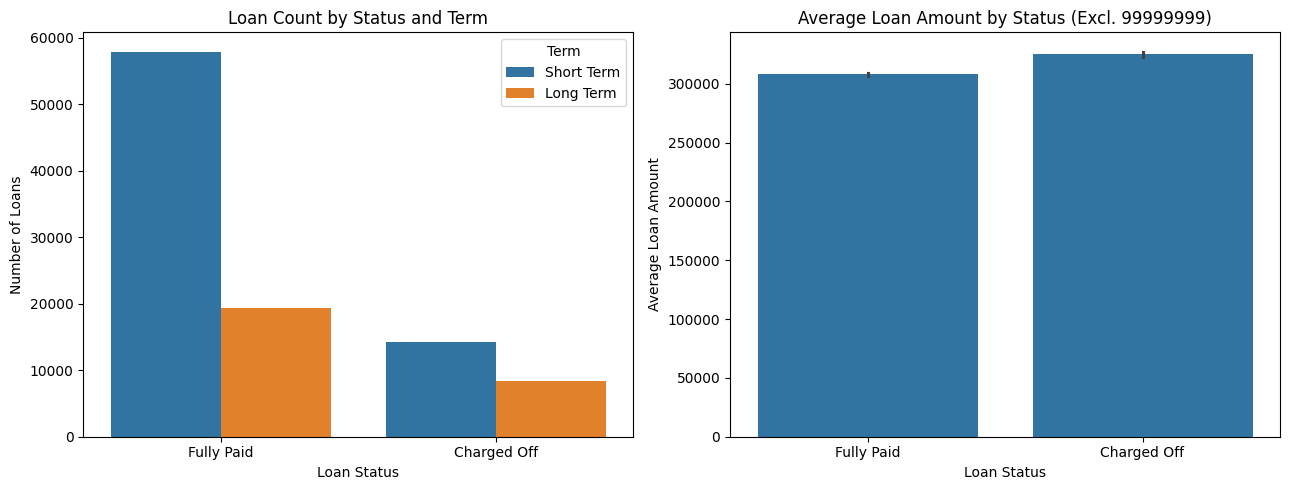

In [37]:
# Filter out placeholder 99999999 values when inspecting/plotting real loan amounts
valid_loan = df_ex5_clean[df_ex5_clean["Current Loan Amount"] < 99999999]

print("Placeholder 99999999 count:", (df_ex5_clean["Current Loan Amount"] >= 99999999).sum())
print("\nAverage loan amount (excluding 99999999) by Loan Status:")
print(valid_loan.groupby("Loan Status")["Current Loan Amount"].mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df_ex5_clean, x="Loan Status", hue="Term", ax=axes[0])
axes[0].set_title("Loan Count by Status and Term")
axes[0].set_xlabel("Loan Status")
axes[0].set_ylabel("Number of Loans")

sns.barplot(data=valid_loan, x="Loan Status", y="Current Loan Amount", ax=axes[1])
axes[1].set_title("Average Loan Amount by Status (Excl. 99999999)")
axes[1].set_xlabel("Loan Status")
axes[1].set_ylabel("Average Loan Amount")

plt.tight_layout()
plt.show()

In [36]:
for col in ["Loan Status", "Term", "Home Ownership", "Purpose"]:
    print(f"\n--- {col} ---")
    print(df_ex5_clean[col].value_counts().head(10))


--- Loan Status ---
Loan Status
Fully Paid     77361
Charged Off    22639
Name: count, dtype: int64

--- Term ---
Term
Short Term    72208
Long Term     27792
Name: count, dtype: int64

--- Home Ownership ---
Home Ownership
Home Mortgage    48410
Rent             42194
Own Home          9182
HaveMortgage       214
Name: count, dtype: int64

--- Purpose ---
Purpose
Debt Consolidation    78552
other                  6037
Home Improvements      5839
Other                  3250
Business Loan          1569
Buy a Car              1265
Medical Bills          1127
Buy House               678
Take a Trip             573
major_purchase          352
Name: count, dtype: int64


### Exercițiul 6
Folosiți setul de date Set6 (exemplul 6 din seminarul 2b).

1. Care sunt cartierele cu cele mai scumpe case? Există acolo case fără instalație de aer condiționat?

Realizați un boxplot cu distribuția prețurilor (`SalePrice`) pentru casele din **top 10%** ca preț (peste cuantila 0,9, calculată cu `quantile`), în funcție de cartiere (`Neighborhood`).

2. Care sunt cartierele cu cele mai ieftine case? Există acolo case fără instalație de aer condiționat? Are vreo relevanță în preț?

Realizați un boxplot cu distribuția prețurilor pentru casele din **bottom 10%** ca preț (sub cuantila 0,1), în funcție de cartiere.

`Atenție` Un boxplot are sens doar dacă are suficiente observații: verificați cu `value_counts` câte case sunt în fiecare cartier și decideți ce cartiere păstrați; explicați decizia.

Shape: (1460, 81) | Has SalePrice: True

0.9 quantile of SalePrice: 278,000.00
Number of houses in top 10%: 145

Neighborhood counts in top 10%:
Neighborhood
NridgHt    48
NoRidge    27
Somerst    13
Timber     12
StoneBr    12
CollgCr     9
Crawfor     7
ClearCr     3
SawyerW     3
Veenker     3
OldTown     3
Gilbert     2
NAmes       1
Edwards     1
NWAmes      1
Name: count, dtype: int64

CentralAir counts in top 10%:
CentralAir
Y    145
Name: count, dtype: int64

CentralAir by Neighborhood (top 10%):
CentralAir     Y
Neighborhood    
ClearCr        3
CollgCr        9
Crawfor        7
Edwards        1
Gilbert        2
NAmes          1
NWAmes         1
NoRidge       27
NridgHt       48
OldTown        3
SawyerW        3
Somerst       13
StoneBr       12
Timber        12
Veenker        3


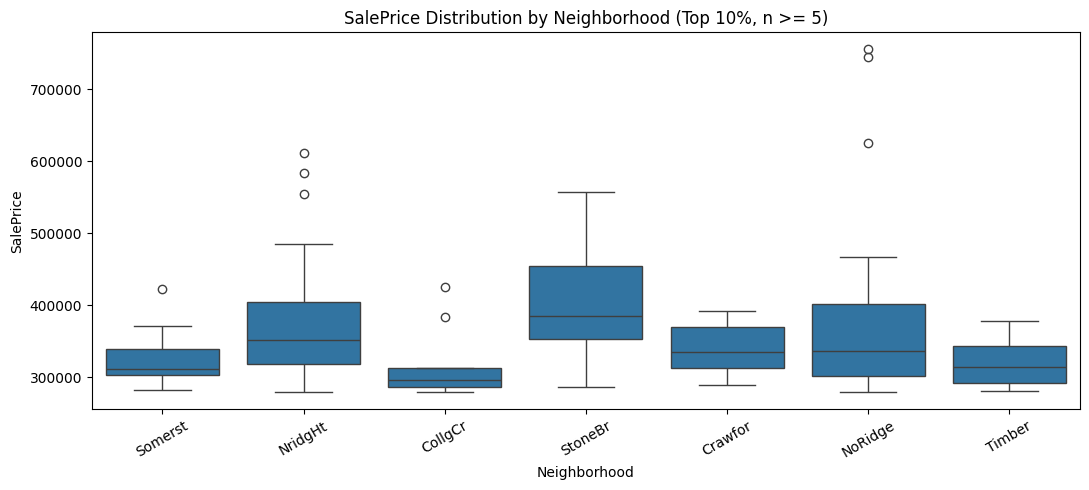

In [42]:
df_ex6 = incarca("lab-set6")[1]
print("Shape:", df_ex6.shape, "| Has SalePrice:", "SalePrice" in df_ex6.columns)

q90 = df_ex6["SalePrice"].quantile(0.9)
top10 = df_ex6[df_ex6["SalePrice"] > q90].copy()

print(f"\n0.9 quantile of SalePrice: {q90:,.2f}")
print("Number of houses in top 10%:", len(top10))

print("\nNeighborhood counts in top 10%:")
print(top10["Neighborhood"].value_counts())

print("\nCentralAir counts in top 10%:")
print(top10["CentralAir"].value_counts(dropna=False))

print("\nCentralAir by Neighborhood (top 10%):")
print(pd.crosstab(top10["Neighborhood"], top10["CentralAir"], dropna=False))

top10_counts = top10["Neighborhood"].value_counts()
keep_top10 = top10_counts[top10_counts >= 5].index
top10_plot = top10[top10["Neighborhood"].isin(keep_top10)]

plt.figure(figsize=(11, 5))
sns.boxplot(data=top10_plot, x="Neighborhood", y="SalePrice")
plt.title("SalePrice Distribution by Neighborhood (Top 10%, n >= 5)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

0.1 quantile of SalePrice: 106,475.00
Number of houses in bottom 10%: 146

Neighborhood counts in bottom 10%:
Neighborhood
OldTown    31
Edwards    29
IDOTRR     19
BrkSide    17
NAmes      14
MeadowV    12
BrDale      9
Sawyer      4
SawyerW     3
SWISU       3
Crawfor     2
Mitchel     2
NWAmes      1
Name: count, dtype: int64

CentralAir counts in bottom 10%:
CentralAir
Y    92
N    54
Name: count, dtype: int64

Average SalePrice by CentralAir in bottom 10%:
            count          mean   median
CentralAir                              
N              54  78963.037037  84250.0
Y              92  90029.130435  90500.0

CentralAir by Neighborhood (bottom 10%):
CentralAir     N   Y
Neighborhood        
BrDale         0   9
BrkSide        7  10
Crawfor        2   0
Edwards       14  15
IDOTRR        12   7
MeadowV        0  12
Mitchel        0   2
NAmes          4  10
NWAmes         0   1
OldTown       11  20
SWISU          2   1
Sawyer         1   3
SawyerW        1   2


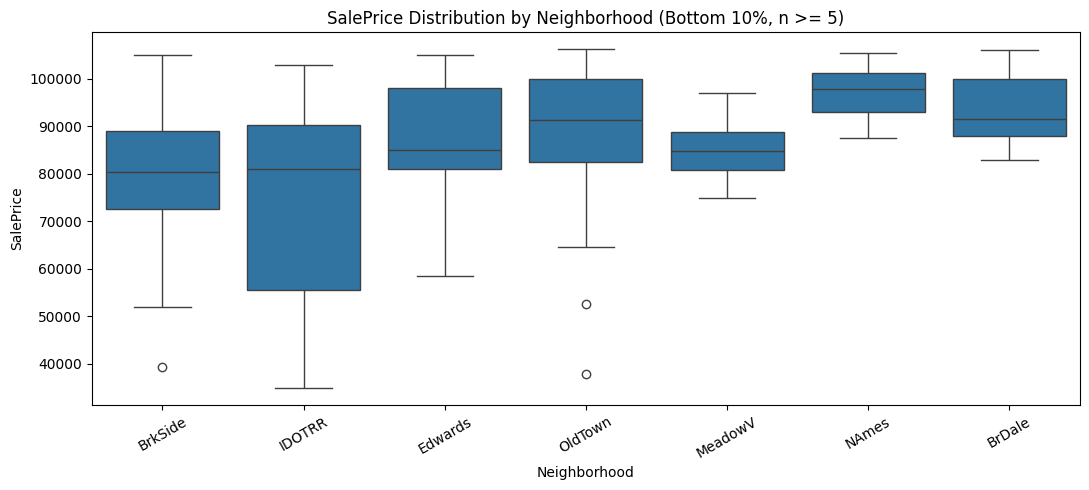

In [43]:
q10 = df_ex6["SalePrice"].quantile(0.1)
bottom10 = df_ex6[df_ex6["SalePrice"] < q10].copy()

print(f"0.1 quantile of SalePrice: {q10:,.2f}")
print("Number of houses in bottom 10%:", len(bottom10))

print("\nNeighborhood counts in bottom 10%:")
print(bottom10["Neighborhood"].value_counts())

print("\nCentralAir counts in bottom 10%:")
print(bottom10["CentralAir"].value_counts(dropna=False))

print("\nAverage SalePrice by CentralAir in bottom 10%:")
print(bottom10.groupby("CentralAir")["SalePrice"].agg(["count", "mean", "median"]))

print("\nCentralAir by Neighborhood (bottom 10%):")
print(pd.crosstab(bottom10["Neighborhood"], bottom10["CentralAir"], dropna=False))

bottom10_counts = bottom10["Neighborhood"].value_counts()
keep_bottom10 = bottom10_counts[bottom10_counts >= 5].index
bottom10_plot = bottom10[bottom10["Neighborhood"].isin(keep_bottom10)]

plt.figure(figsize=(11, 5))
sns.boxplot(data=bottom10_plot, x="Neighborhood", y="SalePrice")
plt.title("SalePrice Distribution by Neighborhood (Bottom 10%, n >= 5)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [44]:
MIN_COUNT = 5  # Minimum houses in a neighborhood to draw a reliable boxplot

print("=== Full dataset (df_ex6) Neighborhood counts ===")
all_counts = df_ex6["Neighborhood"].value_counts()
print(all_counts)

print(f"\n=== Top 10% Neighborhood counts (threshold >= {MIN_COUNT}) ===")
top10_counts = top10["Neighborhood"].value_counts()
print(top10_counts)
kept_top10 = top10_counts[top10_counts >= MIN_COUNT].index.tolist()
print("Kept (top 10%):", kept_top10)

print(f"\n=== Bottom 10% Neighborhood counts (threshold >= {MIN_COUNT}) ===")
bottom10_counts = bottom10["Neighborhood"].value_counts()
print(bottom10_counts)
kept_bottom10 = bottom10_counts[bottom10_counts >= MIN_COUNT].index.tolist()
print("Kept (bottom 10%):", kept10_bottom10)

=== Full dataset (df_ex6) Neighborhood counts ===
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

=== Top 10% Neighborhood counts (threshold >= 5) ===
Neighborhood
NridgHt    48
NoRidge    27
Somerst    13
Timber     12
StoneBr    12
CollgCr     9
Crawfor     7
ClearCr     3
SawyerW     3
Veenker     3
OldTown     3
Gilbert     2
NAmes       1
Edwards     1
NWAmes      1
Name: count, dtype: int64
Kept (top 10%): ['NridgHt', 'NoRidge', 'Somerst', 'Timber', 'StoneBr', 'CollgCr', 'Crawfor']

=== Bottom 10% Neighborhood counts (threshold >= 5) ===
Neighborhood
OldTown    31
Edwards    29
IDOTRR     19
BrkSide    17
NAmes      14


NameError: name 'kept10_bottom10' is not defined

In [46]:
kept_bottom10 = bottom10_counts[bottom10_counts >= MIN_COUNT].index.tolist()
print("Kept (bottom 10%):", kept_bottom10)

print("\nCentralAir counts in bottom 10%:")
print(bottom10["CentralAir"].value_counts(dropna=False))

print("\nSalePrice summary by CentralAir in bottom 10%:")
print(bottom10.groupby("CentralAir")["SalePrice"].agg(["count", "mean", "median"]))

print("\nSalePrice summary by CentralAir across full df_ex6:")
print(df_ex6.groupby("CentralAir")["SalePrice"].agg(["count", "mean", "median"]))

Kept (bottom 10%): ['OldTown', 'Edwards', 'IDOTRR', 'BrkSide', 'NAmes', 'MeadowV', 'BrDale']

CentralAir counts in bottom 10%:
CentralAir
Y    92
N    54
Name: count, dtype: int64

SalePrice summary by CentralAir in bottom 10%:
            count          mean   median
CentralAir                              
N              54  78963.037037  84250.0
Y              92  90029.130435  90500.0

SalePrice summary by CentralAir across full df_ex6:
            count           mean    median
CentralAir                                
N              95  105264.073684   98000.0
Y            1365  186186.709890  168000.0


In [39]:
data_ex6 = incarca("lab-set6")
print("Type:", type(data_ex6), "| Length:", len(data_ex6) if isinstance(data_ex6, (list, tuple)) else "N/A")

if isinstance(data_ex6, (list, tuple)):
    for i, item in enumerate(data_ex6):
        has_price = hasattr(item, "columns") and "SalePrice" in item.columns
        shape = getattr(item, "shape", None)
        print(f"Index [{i}]: shape={shape}, has SalePrice={has_price}")

Type: <class 'seed.date.SetDate'> | Length: N/A


In [15]:
# codul vostru aici
df_ex6 = incarca("lab-set6")[1]
df_ex6.columns

Descărcare lab-set6 (doar prima dată)...


Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

# Jurnal AI

Completați pe scurt, pentru fiecare exercițiu, cum ați lucrat cu asistentul AI.

| Exercițiu | Cererea principală (prompt) | Ce am verificat / corectat | Ce am învățat |
|---|---|---|---|
| 1 |  |  |  |
| 2 |  |  |  |
| 3 |  |  |  |
| 4 |  |  |  |
| 5 |  |  |  |
| 6 |  |  |  |

## Jurnal AI

| Exercițiu | Cererea principală (prompt) | Ce am verificat / corectat | Ce am învățat |
| :--- | :--- | :--- | :--- |
| **1** | Filtrarea rândurilor care nu sunt produse și a prețurilor pozitive (păstrând returnările cu cantitate negativă) pe `lab-set4`, apoi graficul venitului lunar pentru cel mai vândut produs. | Am verificat filtrele astfel încât returnările valide să rămână, iar prețurile invalide și rândurile non-produs să fie excluse. | Cum se curăță datele de tranzacții fără a pierde returnările reale și cum se vizualizează evoluția venitului în timp. |
| **2** | Graficul mediei `MonthlyCharges` pe tipuri de `Contract`, grupat după `gender`, pe `lab-set1`. | Am verificat etichetele categoriilor și valorile agregate pe tipuri de contract și gen. | Cum scot în evidență graficele grupate diferențele dintre medii pe segmente. |
| **3** | Grafice KDE pentru `MonthlyIncome` după `MaritalStatus` și grafice de distribuție alăturate pentru `DistanceFromHome` pe `lab-set2`. | Am verificat forma distribuțiilor, lizibilitatea și așezarea alăturată a graficelor. | Cum ajută KDE și graficele alăturate la compararea asimetriei, împrăștierii și diferențelor dintre grupuri. |
| **4** | Grafice pie și bar pentru `Fjob`, `Medu`, timpul de studiu și timpul de deplasare pe `lab-set3`, plus explicația limitelor graficului pie. | Am verificat când se potrivesc frecvențele/procentajele față de mediile pe grup și am ales tipul potrivit de grafic. | Graficele pie sunt potrivite pentru părți dintr-un întreg (numărători/procente), dar nu pentru compararea mediilor pe grup. |
| **5** | Curățarea setului `lab-set5` (`100.514` rânduri), verificarea valorilor lipsă, tratarea valorii `99999999` la suma împrumutului și grafice pentru număr și medie. | Am eliminat cele `514` rânduri goale (`NaN` pe toate coloanele) rămânând cu `100.000` de înregistrări, am numărat valorile lipsă și am exclus `99999999` la calculul mediei. | Valorile santinelă (`99999999`) și rândurile complet goale pot distorsiona mediile și graficele dacă nu sunt verificate din timp. |
| **6** | Analiza top 10% (`quantile(0.9)`) și bottom 10% (`quantile(0.1)`) pentru `SalePrice` pe `Neighborhood`, verificarea `CentralAir` și boxplot-uri pentru cartierele cu suficiente observații. | Am selectat `incarca("lab-set6")[1]` (partea cu `SalePrice`), am corectat eroarea `kept_bottom10` și am filtrat cartierele cu `count >= 5`. | Un boxplot are sens doar când există suficiente observații pe categorie, iar `CentralAir` are o pondere și o relevanță diferită între locuințele ieftine, cele scumpe și întregul set. |